In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import json

import sys

sys.path.append("../")

##################################################################
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["CUDA_VISIBLE_DEVICES"] = "0,1,2,3,4,5,6,7"
##################################################################

import logging
from src.utils import logging_utils
from src.utils import env_utils
import torch
import transformers
from rich.console import Console
from rich.theme import Theme
import builtins
_orig_print = builtins.print

custom_theme = Theme({"default": "white"})
console = Console(theme=custom_theme, width = 300)


# Override print globally
def print(*args, **kwargs):
    console.print(*args, **kwargs)


logger = logging.getLogger(__name__)

logging.basicConfig(
    level=logging.DEBUG,
    format=logging_utils.DEFAULT_FORMAT,
    datefmt=logging_utils.DEFAULT_DATEFMT,
    stream=sys.stdout,
)

logger.info(f"{torch.__version__=}, {torch.version.cuda=}")
logger.info(
    f"{torch.cuda.is_available()=}, {torch.cuda.device_count()=}, {torch.cuda.get_device_name()=}"
)
logger.info(f"{transformers.__version__=}")

/disk/u/arnab/miniconda3/envs/goals/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026-02-10 12:25:14 __main__ INFO     torch.__version__='2.10.0+cu128', torch.version.cuda='12.8'
2026-02-10 12:25:14 __main__ INFO     torch.cuda.is_available()=True, torch.cuda.device_count()=8, torch.cuda.get_device_name()='NVIDIA A100 80GB PCIe'
2026-02-10 12:25:14 __main__ INFO     transformers.__version__='5.0.0'


In [3]:
from src.models import ModelandTokenizer

# model_key = "allenai/Olmo-3-1125-32B"
# model_key = "allenai/Olmo-3.1-32B-Instruct"
# model_key = "allenai/Olmo-3.1-7B-RL-Zero-Code"

# model_key = "meta-llama/Llama-3.3-70B-Instruct"

# model_key = "deepseek-ai/deepseek-coder-33b-base"
# model_key = "deepseek-ai/DeepSeek-Coder-V2-Lite-Instruct"

# model_key = "openai/gpt-oss-20b"
# model_key = "openai/gpt-oss-120b" #! weird results. known issue.

# model_key = "Qwen/Qwen3-Coder-30B-A3B-Instruct"
# model_key = "Qwen/Qwen2.5-Coder-14B"
# model_key = "Qwen/Qwen2.5-Coder-14B-Instruct"
# model_key = "Qwen/Qwen2.5-Coder-32B"
model_key = "Qwen/Qwen2.5-Coder-32B-Instruct"
# model_key = "Qwen/Qwen2.5-72B"
# model_key = "Qwen/Qwen2.5-72B-Instruct"

# model_key = "bigcode/starcoder2-15b"

# model_key = "zai-org/GLM-4.7-Flash"

mt = ModelandTokenizer(
    model_key=model_key,
    dtype=torch.bfloat16,
    device_map="auto",
    attn_implementation="eager",
)

2026-02-10 12:25:18 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory
2026-02-10 12:25:18 httpcore.connection DEBUG    connect_tcp.started host='huggingface.co' port=443 local_address=None timeout=10 socket_options=None
2026-02-10 12:25:18 httpcore.connection DEBUG    connect_tcp.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7f51eb4c9340>
2026-02-10 12:25:18 httpcore.connection DEBUG    start_tls.started ssl_context=<ssl.SSLContext object at 0x7f51ead1bdd0> server_hostname='huggingface.co' timeout=10
2026-02-10 12:25:18 httpcore.connection DEBUG    start_tls.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7f51eb49a7e0>
2026-02-10 12:25:18 httpcore.http11 DEBUG    send_request_headers.started request=<Request [b'HEAD']>
2026-02-10 12:25:18 httpcore.http11 DEBUG    send_request_headers.complete
2026-02-10 12:25:18 http

Loading weights: 100%|██████████| 771/771 [00:19<00:00, 39.61it/s, Materializing param=model.norm.weight]                              


2026-02-10 12:25:42 httpcore.connection DEBUG    close.started
2026-02-10 12:25:42 httpcore.connection DEBUG    close.complete
2026-02-10 12:25:42 httpcore.connection DEBUG    connect_tcp.started host='huggingface.co' port=443 local_address=None timeout=10 socket_options=None
2026-02-10 12:25:42 httpcore.connection DEBUG    connect_tcp.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7f51e93d0500>
2026-02-10 12:25:42 httpcore.connection DEBUG    start_tls.started ssl_context=<ssl.SSLContext object at 0x7f51ead1bdd0> server_hostname='huggingface.co' timeout=10
2026-02-10 12:25:42 httpcore.connection DEBUG    start_tls.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7f51eb3d1c40>
2026-02-10 12:25:42 httpcore.http11 DEBUG    send_request_headers.started request=<Request [b'HEAD']>
2026-02-10 12:25:42 httpcore.http11 DEBUG    send_request_headers.complete
2026-02-10 12:25:42 httpcore.http11 DEBUG    send_request_body.started request=<Request [b'HE

## Get contrastive branches for one sample

In [4]:
from src.goals.eval import run_evaluation, pretty_print_eval_results
from src.goals.data import IncompleteCodeDataset
from src.tokens import prepare_input
from src.goals.data import CodeGenerations, Code
from src.goals.functional import supports_chat_template, apply_chat_template
from src.functional import generate_with_patch


SAMPLE_IDX = 5

eval_dataset = IncompleteCodeDataset.load_dataset()
print(eval_dataset[SAMPLE_IDX])

sample = eval_dataset[SAMPLE_IDX]
instruction = sample.instruction
unfinished_code = sample.code
function_name = sample.function_name or "func"
unit_tests = sample.unit_tests
prefills = []
for ptype, pfill_list in sample.prefills.items():
    prefills.extend([prefill, ptype] for prefill in pfill_list)


if supports_chat_template(mt):
    prompts = [
        apply_chat_template(
            mt=mt,
            user_query=instruction.strip(),
            incomplete_code=unfinished_code + prefill,
        )
        for prefill, ptype in prefills
    ]
else:
    prompts = [
        instruction + "<code>" + unfinished_code + prefill
        for (prefill, ptype) in prefills
    ]


inputs = prepare_input(
    prompts=prompts,
    tokenizer=mt,
)

output = generate_with_patch(
    mt=mt,
    inputs=inputs,
    n_gen_per_prompt=1,
    max_new_tokens=64,
    do_sample=False,
    remove_prefix=True,
)

results = CodeGenerations(
    sample=sample,
    generations=[
        Code(prefill=prefill, prefill_type=ptype, full_prompt=inp, lm_generation=out)
        for (prefill, ptype), inp, out in zip(prefills, prompts, output)
    ],
)

# print(f"[white]{str(results)}[/white]")

eval_results = run_evaluation(
    result = results,
    function_name=function_name,
    code_stop_tag="</code>",
)

# Print results in tabular format
pretty_print_eval_results(eval_results)

2026-02-10 12:25:43 src.goals.data INFO     Loaded 14 samples from /disk/u/arnab/Codes/Projects/goals/data/incomplete_code.json


IncompleteCodeSample(
    instruction='Write a function in python that checks if a string is a palindrome.\n\n',
    code='def is_palindrome(s: str) -> bool:\n    return True if ',
    unit_tests=[('racecar', True), ('hello', False), ('', True), ('a', True), ('ab', False), ('aba', True), ('abba', True)],
    prefills={'aligned': ['', '(', 's', 's ==', 's == s', 's[::', 's[::-1]', '(s', 'list(', 'list(s)'], 'adversarial': ['not', 'not (', 's +', '3', '1 +'], 'inconsequential': ['bool(', 'True and', 'False or', '0 +']},
    function_name='is_palindrome'
)

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
You have set `compile_config`, but we are unable to meet the criteria for compilation. Compilation will be skipped.


True
False
True
False
True
False
True
False
True
False
True
False
True
False
True
False
True
False
True
False
True
False
True
False
True
False
True
False
True
False
True
False


"""def is_palindrome(s: str) -> bool:
    return True if """

                                                                                Code Completion Results                                                                                
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Prefill                     ┃ Logic                                                          ┃ Verdict ┃ Unit Tests ┃ Logs                                                          ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ aligned: ""                 │ " s == s[::-1] else False                                      │ PASSED  │            │                                                               │
│                             │                                                                │         │            │                                                               │
│                             │ # Example usage:                                               │         │            │                                                               │
│                             │ print(is_palindrome("racecar"))  # Output: True                │         │            │                                                               │
│                             │ print(is_palindrome("hello"))    # Output: False"              │         │            │                                                               │
├─────────────────────────────┼────────────────────────────────────────────────────────────────┼─────────┼────────────┼───────────────────────────────────────────────────────────────┤
│ aligned: "("                │ "(s == s[::-1]) else False                                     │ PASSED  │            │                                                               │
│                             │                                                                │         │            │                                                               │
│                             │ # Example usage:                                               │         │            │                                                               │
│                             │ print(is_palindrome("racecar"))  # Output: True                │         │            │                                                               │
│                             │ print(is_palindrome("hello"))    # Output: False"              │         │            │                                                               │
├─────────────────────────────┼────────────────────────────────────────────────────────────────┼─────────┼────────────┼───────────────────────────────────────────────────────────────┤
│ aligned: "s"                │ "s == s[::-1] else False                                       │ PASSED  │            │                                                               │
│                             │                                                                │         │            │                                                               │
│                             │ # Example usage:                                               │         │            │                                                               │
│                             │ print(is_palindrome("racecar"))  # Output: True                │         │            │                                                               │
│                             │ print(is_palindrome("hello"))    # Output: False"              │         │            │                                                               │
├─────────────────────────────┼────────────────────────────────────────────────────────────────┼─────────┼────────────┼─────────────────

Summary: 17/19 passed, 2/19 failed

In [5]:
from dataclasses import dataclass, field
from dataclasses_json import DataClassJsonMixin
from typing import Any

@dataclass
class MCTSResult(DataClassJsonMixin):
    """
    Results from a single MCTS search + evaluation + contrastive sampling.
    Serializable via DataClassJsonMixin (.to_dict() / .from_dict()).
    
    The MCTS tree itself is not serialized (MCTSNode objects are not JSON-friendly).
    Instead, we store the contrastive pairs as text paths + outcome probs,
    and optionally save the tree as HTML via search.save_tree().
    """
    # Identification
    model_name: str = ""
    sample_idx: int = 0
    prefill: str = ""
    prefill_type: str = ""
    function_name: str = "func"
    
    # Prompt info
    prompt: str = ""                     # full prompt sent to LM
    prefix: str = ""                     # sample.code + prefill (for eval)
    
    # MCTS config & stats
    mcts_config: dict[str, Any] = field(default_factory=dict)
    mcts_stats: dict[str, Any] = field(default_factory=dict)
    
    # Evaluation counts {"green": N, "orange": N, "red": N, "total": N}
    eval_counts: dict[str, int] = field(default_factory=dict)
    
    # Contrastive pairs: depth (str key) -> list of {pos_path, neg_path, pos_probs, neg_probs}
    contrastive_pairs: dict[str, list[dict[str, Any]]] = field(default_factory=dict)
    
    # Sampling thresholds used
    sampling_config: dict[str, Any] = field(default_factory=dict)
    
    def save(self, filepath: str) -> None:
        os.makedirs(os.path.dirname(filepath), exist_ok=True)
        with open(filepath, "w") as f:
            json.dump(self.to_dict(), f, indent=2)
    
    @classmethod
    def load(cls, filepath: str) -> "MCTSResult":
        with open(filepath, "r") as f:
            return cls.from_dict(json.load(f))
    
    @property
    def total_pairs(self) -> int:
        return sum(len(p) for p in self.contrastive_pairs.values())
    
    @property
    def depths_with_pairs(self) -> list[int]:
        return sorted(int(d) for d in self.contrastive_pairs if self.contrastive_pairs[d])


# Quick test: round-trip serialization
_test = MCTSResult(model_name="test", sample_idx=0, prefill="x")
assert MCTSResult.from_dict(_test.to_dict()).model_name == "test"
print("MCTSResult serialization OK")

MCTSResult serialization OK

In [6]:
from src.goals.sampling import MCTSSearch
from src.goals.eval import evaluate_mcts_tree
from src.goals.probe import sample_multidepth_pairs, print_contrastive_pairs
from src.utils.env_utils import DEFAULT_RESULTS_DIR
from dataclasses import asdict

# --- Config ---
MCTS_ITERATIONS = 1500
MCTS_MAX_DEPTH = 20
MCTS_TOP_K = 10
MCTS_PROB_THRESHOLD = 0.01
DEPTH_FIRST = True

SAMPLING_CONFIG = dict(
    min_depth=1,
    max_depth=10,
    min_green_confidence=0.5,
    max_red_in_positive=0.3,
    min_red_confidence=0.5,
    max_green_in_negative=0.1,
    max_uncertain=0.5,
)

model_short_name = mt.name.split("/")[-1]
save_dir = os.path.join(DEFAULT_RESULTS_DIR, "probe", model_short_name, f"sample_{SAMPLE_IDX}")
mcts_dir = os.path.join(save_dir, "MCTS")
os.makedirs(save_dir, exist_ok=True)
os.makedirs(mcts_dir, exist_ok=True)
# --- Run MCTS + eval + contrastive sampling for each prefill ---
all_results: list[MCTSResult] = []

for prefill_idx, (prefill_val, prefill_type) in enumerate(prefills):
    _orig_print(f"\n{'='*60}")
    _orig_print(f"Prefill {prefill_idx}/{len(prefills)}: ({prefill_type}) {prefill_val!r}")
    _orig_print(f"{'='*60}")
    
    prompt = prompts[prefill_idx]
    prefix = sample.code + prefill_val
    
    # 1) MCTS search
    search = MCTSSearch(
        mt=mt,
        prompt=prompt,
        max_depth=MCTS_MAX_DEPTH,
        top_k=MCTS_TOP_K,
        prob_threshold=MCTS_PROB_THRESHOLD,
    )
    root = search.run(n_iterations=MCTS_ITERATIONS, depth_first=DEPTH_FIRST)
    
    # 2) Evaluate tree
    counts = evaluate_mcts_tree(
        root=search.root,
        prefix=prefix,
        unit_tests=sample.unit_tests,
        function_name=function_name,
        terminal_only=False,
    )
    _orig_print(f"  Eval counts: {counts}")
    
    # 3) Sample contrastive pairs
    pairs_by_depth = sample_multidepth_pairs(root=search.root, **SAMPLING_CONFIG)
    n_pairs = sum(len(p) for p in pairs_by_depth.values())
    _orig_print(f"  Contrastive pairs: {n_pairs}")
    
    # 4) Serialize contrastive pairs (MCTSNode -> text paths)
    serialized_pairs = {}
    for depth, pairs in pairs_by_depth.items():
        serialized_pairs[str(depth)] = [
            {
                "pos_path": pair.positive.get_path_text(),
                "neg_path": pair.negative.get_path_text(),
                "pos_probs": {"green": pair.pos_probs.green, "red": pair.pos_probs.red, "uncertain": pair.pos_probs.uncertain},
                "neg_probs": {"green": pair.neg_probs.green, "red": pair.neg_probs.red, "uncertain": pair.neg_probs.uncertain},
            }
            for pair in pairs
        ]
    
    # 5) Build result
    result = MCTSResult(
        model_name=model_short_name,
        sample_idx=SAMPLE_IDX,
        prefill=prefill_val,
        prefill_type=prefill_type,
        function_name=function_name,
        prompt=prompt,
        prefix=prefix,
        mcts_config=dict(
            iterations=MCTS_ITERATIONS, max_depth=MCTS_MAX_DEPTH,
            top_k=MCTS_TOP_K, prob_threshold=MCTS_PROB_THRESHOLD,
            depth_first=DEPTH_FIRST,
        ),
        mcts_stats=search.get_stats(),
        eval_counts=counts,
        contrastive_pairs=serialized_pairs,
        sampling_config=SAMPLING_CONFIG,
    )
    all_results.append(result)
    
    # 6) Save to disk
    safe_prefill_name = prefill_val.replace(" ", "_").replace("/", "_") or "empty"
    result_path = os.path.join(mcts_dir, f"prefill_{prefill_idx}_{safe_prefill_name}.json")
    result.save(result_path)
    
    # Also save tree HTML
    tree_path = os.path.join(mcts_dir, f"prefill_{prefill_idx}_{safe_prefill_name}_tree.html")
    search.save_tree(tree_path, show_colors=True)

print(f"\n[bold]Done! Saved {len(all_results)} results to {mcts_dir}[/bold]")
print(f"Total contrastive pairs across all prefills: {sum(r.total_pairs for r in all_results)}")


Prefill 0/19: (aligned) ''
2026-02-10 12:25:54 src.goals.sampling DEBUG    MCTS iteration 50/1500, total nodes: 35
2026-02-10 12:25:56 src.goals.sampling DEBUG    MCTS iteration 100/1500, total nodes: 56
2026-02-10 12:25:56 src.goals.sampling DEBUG    MCTS iteration 150/1500, total nodes: 56
2026-02-10 12:25:56 src.goals.sampling DEBUG    MCTS iteration 200/1500, total nodes: 56
2026-02-10 12:25:56 src.goals.sampling DEBUG    MCTS iteration 250/1500, total nodes: 56
2026-02-10 12:25:56 src.goals.sampling DEBUG    MCTS iteration 300/1500, total nodes: 56
2026-02-10 12:25:56 src.goals.sampling DEBUG    MCTS iteration 350/1500, total nodes: 56
2026-02-10 12:25:56 src.goals.sampling DEBUG    MCTS iteration 400/1500, total nodes: 56
2026-02-10 12:25:56 src.goals.sampling DEBUG    MCTS iteration 450/1500, total nodes: 56
2026-02-10 12:25:56 src.goals.sampling DEBUG    MCTS iteration 500/1500, total nodes: 56
2026-02-10 12:25:56 src.goals.sampling DEBUG    MCTS iteration 550/1500, total node

Done! Saved 19 results to /disk/u/arnab/Codes/Projects/goals/results/probe/Qwen2.5-Coder-32B-Instruct/sample_5/MCTS

Total contrastive pairs across all prefills: 86526

## extract latents

In [7]:
@torch.inference_mode()
def get_last_token_latents_batch(
    mt: ModelandTokenizer,
    texts: list[str],
    layers: list[int] | None = None,
) -> dict[int, torch.Tensor]:
    """
    Extract residual stream hidden states at the last token position for a batch of inputs.
    
    Simplified and batched alternative to get_hs — no interventions, only grabs
    the last (non-padding) token's residual stream across specified layers.
    
    Each layer's output stays on its native GPU (no cross-device stacking).
    
    Args:
        mt: ModelandTokenizer instance
        texts: List of input strings
        layers: Layer indices to extract from. None = all layers.
    
    Returns:
        Dict mapping layer_idx -> Tensor of shape (batch, hidden_dim) on that layer's device.
    """
    if layers is None:
        layers = list(range(mt.n_layer))
    
    # Tokenize with left-padding so the last non-pad token is always at position -1
    inputs = prepare_input(prompts=texts, tokenizer=mt, padding_side="left")
    
    # Set up nnsight trace to capture layer outputs
    layer_saves = {}
    with mt.trace(inputs, scan=False):
        for layer_idx in layers:
            layer_name = mt.layer_name_format.format(layer_idx)
            module = mt
            for attr in layer_name.split("."):
                module = module[int(attr)] if attr.isdigit() else getattr(module, attr)
            output = module.output
            # Some architectures wrap output in a tuple
            if isinstance(output, tuple) or (hasattr(output, '__len__') and not hasattr(output, 'shape')):
                output = output[0]
            layer_saves[layer_idx] = output[:, -1, :].save()  # (batch, hidden_dim)
    
    # Return per-layer tensors, each staying on its native device
    return {l: layer_saves[l].float() for l in layers}


# Quick test
_test_hs = get_last_token_latents_batch(mt, [prompts[0], prompts[1]], layers=[0, mt.n_layer - 1])
for l, t in _test_hs.items():
    print(f"Layer {l}: shape={t.shape}, device={t.device}")
print(f"All layers for 1 input would give {mt.n_layer} tensors of shape (1, {mt.n_embd})")

Layer 0: shape=torch.Size([2, 5120]), device=cuda:0

Layer 63: shape=torch.Size([2, 5120]), device=cuda:7

All layers for 1 input would give 64 tensors of shape (1, 5120)

In [8]:
import random
from collections import Counter, defaultdict

# --- 1) Collect all contrastive pairs, tagged by prefill_idx ---

pair_records = []

for prefill_idx, result in enumerate(all_results):
    for depth_str, pairs in result.contrastive_pairs.items():
        for pair in pairs:
            pair_records.append({
                "prompt": result.prompt,
                "prefix": result.prefix,
                "pos_path": pair["pos_path"],
                "neg_path": pair["neg_path"],
                "depth": int(depth_str),
                "prefill_idx": prefill_idx,
                "prefill": result.prefill,
                "prefill_type": result.prefill_type,
            })

n_pairs_total = len(pair_records)
_orig_print(f"Total contrastive pair records: {n_pairs_total}")

# Show distribution by depth
depth_counts = Counter(r["depth"] for r in pair_records)
for d in sorted(depth_counts):
    _orig_print(f"  Depth {d}: {depth_counts[d]} pairs")

# --- 2) Tree/prefill-level train/test split ---
# Reserve entire trees for test. At least 1 of each prefill type in test.
# Only consider prefills that have >0 contrastive pairs.

# Count pairs per prefill
pairs_per_prefill: dict[int, int] = Counter(r["prefill_idx"] for r in pair_records)

# Group prefill indices by type, only those with pairs
prefill_type_to_indices: dict[str, list[int]] = defaultdict(list)
for idx, result in enumerate(all_results):
    if pairs_per_prefill.get(idx, 0) > 0:
        prefill_type_to_indices[result.prefill_type].append(idx)

random.seed(42)
test_prefill_set: set[int] = set()
for ptype, indices in prefill_type_to_indices.items():
    if len(indices) == 0:
        _orig_print(f"  WARNING: no prefills with pairs for type '{ptype}', skipping")
        continue
    if len(indices) == 1:
        # Only 1 prefill with pairs for this type — must keep it for train
        _orig_print(f"  WARNING: only 1 prefill with pairs for type '{ptype}' (idx={indices[0]}), keeping in train")
        continue
    test_prefill_set.add(random.choice(indices))

train_prefill_set = set(range(len(all_results))) - test_prefill_set

# Build pair-level indices from the prefill-level split
train_idx = [i for i, rec in enumerate(pair_records) if rec["prefill_idx"] in train_prefill_set]
test_idx = [i for i, rec in enumerate(pair_records) if rec["prefill_idx"] in test_prefill_set]

# --- Print split summary ---
_orig_print(f"\n{'='*60}")
_orig_print(f"Tree-level train/test split (no latent leakage)")
_orig_print(f"{'='*60}")
_orig_print(f"Train prefills ({len(train_prefill_set)}):")
for idx in sorted(train_prefill_set):
    r = all_results[idx]
    n = pairs_per_prefill.get(idx, 0)
    _orig_print(f"  [{idx:>2}] ({r.prefill_type:>16}) {r.prefill!r:<15} -> {n} pairs")

_orig_print(f"Test prefills ({len(test_prefill_set)}):")
for idx in sorted(test_prefill_set):
    r = all_results[idx]
    n = pairs_per_prefill.get(idx, 0)
    _orig_print(f"  [{idx:>2}] ({r.prefill_type:>16}) {r.prefill!r:<15} -> {n} pairs")

_orig_print(f"\nTrain pairs: {len(train_idx)}, Test pairs: {len(test_idx)}")
if len(test_idx) == 0:
    _orig_print("WARNING: 0 test pairs! All prefill types may have <=1 prefill with pairs.")

Total contrastive pair records: 86526
  Depth 1: 23 pairs
  Depth 2: 249 pairs
  Depth 3: 1353 pairs
  Depth 4: 3023 pairs
  Depth 5: 5161 pairs
  Depth 6: 7814 pairs
  Depth 7: 11690 pairs
  Depth 8: 15553 pairs
  Depth 9: 20354 pairs
  Depth 10: 21306 pairs

Tree-level train/test split (no latent leakage)
Train prefills (16):
  [ 0] (         aligned) ''              -> 0 pairs
  [ 2] (         aligned) 's'             -> 0 pairs
  [ 3] (         aligned) 's =='          -> 0 pairs
  [ 4] (         aligned) 's == s'        -> 0 pairs
  [ 5] (         aligned) 's[::'          -> 0 pairs
  [ 6] (         aligned) 's[::-1]'       -> 0 pairs
  [ 7] (         aligned) '(s'            -> 0 pairs
  [ 8] (         aligned) 'list('         -> 15228 pairs
  [ 9] (         aligned) 'list(s)'       -> 0 pairs
  [11] (     adversarial) 'not ('         -> 3601 pairs
  [12] (     adversarial) 's +'           -> 1003 pairs
  [13] (     adversarial) '3'             -> 14292 pairs
  [14] (     adversa

In [9]:
# --- 2) Extract latents for all contrastive pairs (batched) ---
# For each pair, we feed prompt + pos_path and prompt + neg_path,
# extract hidden states at last token position for all layers.
# Latents are stored per-layer, each on its native GPU.

LAYERS_TO_PROBE = list(range(mt.n_layer))  # all layers; narrow down later
BATCH_SIZE = 32  # number of texts per forward pass (adjust based on GPU memory)

# Build flat list of all texts to process
pos_texts = [rec["prompt"] + rec["pos_path"] for rec in pair_records]
neg_texts = [rec["prompt"] + rec["neg_path"] for rec in pair_records]
all_texts = pos_texts + neg_texts  # 2 * n_pairs texts total

n_total = len(all_texts)
n_pairs_total = len(pair_records)
_orig_print(f"Extracting latents for {n_total} texts ({n_pairs_total} pairs) in batches of {BATCH_SIZE}...")

# Accumulate per-layer: layer_idx -> list of (batch_size, hidden_dim) tensors
latents_by_layer: dict[int, list[torch.Tensor]] = {l: [] for l in LAYERS_TO_PROBE}

for batch_start in range(0, n_total, BATCH_SIZE):
    batch_texts = all_texts[batch_start : batch_start + BATCH_SIZE]
    if batch_start % (BATCH_SIZE * 10) == 0:
        _orig_print(f"  Batch {batch_start // BATCH_SIZE + 1}/{(n_total + BATCH_SIZE - 1) // BATCH_SIZE}...")
    
    batch_hs = get_last_token_latents_batch(mt, batch_texts, layers=LAYERS_TO_PROBE)
    for l in LAYERS_TO_PROBE:
        latents_by_layer[l].append(batch_hs[l])

# Concatenate per-layer: layer_idx -> (2*n_pairs, hidden_dim) on that layer's device
# Then split into pos/neg per layer
Z_pos_by_layer: dict[int, torch.Tensor] = {}  # layer -> (n_pairs, hidden_dim)
Z_neg_by_layer: dict[int, torch.Tensor] = {}  # layer -> (n_pairs, hidden_dim)

for l in LAYERS_TO_PROBE:
    all_l = torch.cat(latents_by_layer[l], dim=0)  # (2*n_pairs, hidden_dim), same device
    Z_pos_by_layer[l] = all_l[:n_pairs_total]
    Z_neg_by_layer[l] = all_l[n_pairs_total:]

del latents_by_layer  # free the intermediate lists

# Print summary
_sample_layer = LAYERS_TO_PROBE[0]
print(f"Per-layer tensors: {len(Z_pos_by_layer)} layers")
print(f"  Layer {_sample_layer}: Z_pos {Z_pos_by_layer[_sample_layer].shape} on {Z_pos_by_layer[_sample_layer].device}")
_last_layer = LAYERS_TO_PROBE[-1]
print(f"  Layer {_last_layer}: Z_pos {Z_pos_by_layer[_last_layer].shape} on {Z_pos_by_layer[_last_layer].device}")

Extracting latents for 173052 texts (86526 pairs) in batches of 32...
  Batch 1/5408...
  Batch 11/5408...
  Batch 21/5408...
  Batch 31/5408...
  Batch 41/5408...
  Batch 51/5408...
  Batch 61/5408...
  Batch 71/5408...
  Batch 81/5408...
  Batch 91/5408...
  Batch 101/5408...
  Batch 111/5408...
  Batch 121/5408...
  Batch 131/5408...
  Batch 141/5408...
  Batch 151/5408...
  Batch 161/5408...
  Batch 171/5408...
  Batch 181/5408...
  Batch 191/5408...
  Batch 201/5408...
  Batch 211/5408...
  Batch 221/5408...
  Batch 231/5408...
  Batch 241/5408...
  Batch 251/5408...
  Batch 261/5408...
  Batch 271/5408...
  Batch 281/5408...
  Batch 291/5408...
  Batch 301/5408...
  Batch 311/5408...
  Batch 321/5408...
  Batch 331/5408...
  Batch 341/5408...
  Batch 351/5408...
  Batch 361/5408...
  Batch 371/5408...
  Batch 381/5408...
  Batch 391/5408...
  Batch 401/5408...
  Batch 411/5408...
  Batch 421/5408...
  Batch 431/5408...
  Batch 441/5408...
  Batch 451/5408...
  Batch 461/5408...
 

Per-layer tensors: 64 layers

Layer 0: Z_pos torch.Size([86526, 5120]) on cuda:0

Layer 63: Z_pos torch.Size([86526, 5120]) on cuda:7

## Train goal directions

In [10]:
# --- 3) Baseline: mean difference goal direction per layer ---
# For each layer l independently, find a direction v_l such that v_l · z⁺ > v_l · z⁻
# Baseline: v_l = mean(z⁺_l) - mean(z⁻_l), normalized.
# Each layer gets its own independent goal direction, stored on that layer's device.
# train_idx / test_idx are from tree-level split (no latent leakage).

n_pairs = n_pairs_total
n_layers = len(LAYERS_TO_PROBE)

_orig_print(f"Train pairs: {len(train_idx)}, Test pairs: {len(test_idx)}")

# --- Compute and store goal direction per layer ---
goal_directions: dict[int, torch.Tensor] = {}   # layer -> (hidden_dim,) on layer's device
train_accuracies: dict[int, float] = {}
test_accuracies: dict[int, float] = {}

for layer_idx in LAYERS_TO_PROBE:
    z_pos_l = Z_pos_by_layer[layer_idx]  # (n_pairs, hidden_dim) on layer's device
    z_neg_l = Z_neg_by_layer[layer_idx]
    
    # Goal direction for this layer: mean difference on train set
    z_pos_train = z_pos_l[train_idx]
    z_neg_train = z_neg_l[train_idx]
    
    v_l = z_pos_train.mean(dim=0) - z_neg_train.mean(dim=0)
    v_l = v_l / (v_l.norm() + 1e-8)
    goal_directions[layer_idx] = v_l
    
    # Train accuracy: fraction of pairs where v_l · z⁺ > v_l · z⁻
    train_acc = (z_pos_train @ v_l > z_neg_train @ v_l).float().mean().item()
    train_accuracies[layer_idx] = train_acc
    
    # Test accuracy
    z_pos_test = z_pos_l[test_idx]
    z_neg_test = z_neg_l[test_idx]
    test_acc = (z_pos_test @ v_l > z_neg_test @ v_l).float().mean().item()
    test_accuracies[layer_idx] = test_acc

print(f"\ngoal_directions: {len(goal_directions)} layers, each on its native device")
print(f"\nConstraint accuracy (v_l · z⁺ > v_l · z⁻) per layer:")
print(f"{'Layer':>6} {'Train':>8} {'Test':>8} {'Device':>10}")
print(f"{'-----':>6} {'-----':>8} {'-----':>8} {'------':>10}")
for l in LAYERS_TO_PROBE:
    marker = " <--" if test_accuracies[l] >= 0.8 else ""
    _orig_print(f"{l:>6} {train_accuracies[l]:>8.3f} {test_accuracies[l]:>8.3f} {str(goal_directions[l].device):>10}{marker}")

Train pairs: 76000, Test pairs: 10526


goal_directions: 64 layers, each on its native device

Constraint accuracy (v_l · z⁺ > v_l · z⁻) per layer:

Layer    Train     Test     Device

-----    -----    -----     ------

     0    0.681    0.661     cuda:0
     1    0.684    0.667     cuda:0
     2    0.687    0.670     cuda:0
     3    0.697    0.678     cuda:0
     4    0.710    0.689     cuda:0
     5    0.715    0.697     cuda:0
     6    0.714    0.688     cuda:1
     7    0.712    0.687     cuda:1
     8    0.707    0.677     cuda:1
     9    0.708    0.681     cuda:1
    10    0.706    0.680     cuda:1
    11    0.711    0.682     cuda:1
    12    0.716    0.672     cuda:1
    13    0.719    0.676     cuda:1
    14    0.725    0.674     cuda:1
    15    0.731    0.672     cuda:2
    16    0.738    0.676     cuda:2
    17    0.738    0.675     cuda:2
    18    0.737    0.676     cuda:2
    19    0.738    0.672     cuda:2
    20    0.735    0.664     cuda:2
    21    0.734    0.658     cuda:2
    22    0.737    0.658     cuda:2
    23    0.742    0.661     cuda:2
    24    0.740    0.659     cuda:3
    25    0.739    0.661     cuda:3
    26    0.736    0.662     cuda:3
    27    0.739    0.667    

In [11]:
# --- Contrastive objective (Schut et al. Section 4.1.2) ---
# Find v_l that satisfies v_l · z⁺ ≥ v_l · z⁻ + margin.
# Objective: min  λ₁||v||₁ + λ₂||v||₂² + (1/N) Σᵢ max(0, margin - v·(z⁺ᵢ - z⁻ᵢ))
# Setting both lambdas to 0 gives pure hinge loss (no regularization).

@torch.enable_grad()
def learn_contrastive_direction(
    z_pos: torch.Tensor,       # (n_pairs, hidden_dim) on some device
    z_neg: torch.Tensor,       # (n_pairs, hidden_dim) on same device
    l1_lambda: float = 0.0,
    l2_lambda: float = 1e-3,
    margin: float = 1.0,
    lr: float = 1e-2,
    n_steps: int = 1000,
    patience: int = 50,
) -> tuple[torch.Tensor, dict]:
    """
    Learn a goal direction via the contrastive objective.
    
    Minimizes:  λ₁||v||₁ + λ₂||v||₂² + (1/N) Σᵢ max(0, margin - v·(z⁺ᵢ - z⁻ᵢ))
    
    - L1 encourages sparsity (neuron-basis assumption, strong).
    - L2 encourages small norm without basis assumptions.
    - Both at 0 = pure hinge loss, no regularization.
    
    Args:
        z_pos: Positive latents (n_pairs, hidden_dim)
        z_neg: Negative latents (n_pairs, hidden_dim)
        l1_lambda: L1 regularization strength (sparsity)
        l2_lambda: L2 regularization strength (norm penalty)
        margin: Hinge loss margin
        lr: Learning rate for Adam
        n_steps: Maximum optimization steps
        patience: Early stopping patience (steps without improvement)
    
    Returns:
        v: Normalized goal direction (hidden_dim,) on same device
        info: Dict with optimization stats
    """
    device = z_pos.device
    hidden_dim = z_pos.shape[1]
    
    # Precompute difference vectors
    delta = z_pos - z_neg  # (n_pairs, hidden_dim)
    
    # Initialize v with small random values
    v = torch.randn(hidden_dim, device=device, dtype=z_pos.dtype) * 0.01
    v.requires_grad_(True)
    
    optimizer = torch.optim.Adam([v], lr=lr)
    
    best_loss = float('inf')
    patience_counter = 0
    final_step = n_steps
    
    for step in range(n_steps):
        optimizer.zero_grad()
        
        scores = delta @ v                                    # (n_pairs,)
        hinge_loss = torch.clamp(margin - scores, min=0).mean()
        
        # Regularization terms (only computed if lambda > 0)
        reg_loss = torch.zeros(1, device=device, dtype=z_pos.dtype)
        if l1_lambda > 0:
            reg_loss = reg_loss + l1_lambda * v.abs().sum()
        if l2_lambda > 0:
            reg_loss = reg_loss + l2_lambda * (v @ v)         # ||v||₂²
        
        loss = hinge_loss + reg_loss.squeeze()
        
        loss.backward()
        optimizer.step()
        
        curr_loss = loss.item()
        if curr_loss < best_loss - 1e-6:
            best_loss = curr_loss
            patience_counter = 0
        else:
            patience_counter += 1
        
        if patience_counter >= patience:
            final_step = step + 1
            break
    
    with torch.no_grad():
        v_final = v.detach()
        v_norm = v_final.norm()
        v_normalized = v_final / (v_norm + 1e-8)
        
        # Stats
        scores_final = delta @ v_normalized
        constraint_sat = (scores_final > 0).float().mean().item()
        sparsity = (v_normalized.abs() < 1e-2).float().mean().item()
    
    return v_normalized, {
        "final_loss": best_loss,
        "steps": final_step,
        "constraint_satisfaction": constraint_sat,
        "sparsity": sparsity,
        "v_norm_pre_normalize": v_norm.item(),
    }


print("learn_contrastive_direction defined (with L1 + L2 regularization)")

learn_contrastive_direction defined (with L1 + L2 regularization)

In [12]:
# --- Run contrastive objective per layer ---
# Uses the same train/test split as the baseline.

L1_LAMBDA = 0.0     # sparsity (neuron-basis assumption); 0 = off
L2_LAMBDA = 1e-3    # norm penalty (basis-free); 0 = off
MARGIN = 1.0
LR = 1e-2
N_STEPS = 1000

contrastive_directions: dict[int, torch.Tensor] = {}
contrastive_train_accs: dict[int, float] = {}
contrastive_test_accs: dict[int, float] = {}
contrastive_infos: dict[int, dict] = {}

reg_desc = []
if L1_LAMBDA > 0: reg_desc.append(f"λ₁={L1_LAMBDA}")
if L2_LAMBDA > 0: reg_desc.append(f"λ₂={L2_LAMBDA}")
if not reg_desc: reg_desc.append("no regularization")
_orig_print(f"Learning contrastive directions for {n_layers} layers ({', '.join(reg_desc)}, margin={MARGIN})...")

for layer_idx in LAYERS_TO_PROBE:
    z_pos_l = Z_pos_by_layer[layer_idx]
    z_neg_l = Z_neg_by_layer[layer_idx]
    
    z_pos_train = z_pos_l[train_idx]
    z_neg_train = z_neg_l[train_idx]
    
    v_l, info = learn_contrastive_direction(
        z_pos_train, z_neg_train,
        l1_lambda=L1_LAMBDA, l2_lambda=L2_LAMBDA,
        margin=MARGIN, lr=LR, n_steps=N_STEPS,
    )
    contrastive_directions[layer_idx] = v_l
    contrastive_infos[layer_idx] = info
    
    # Train accuracy
    train_acc = (z_pos_train @ v_l > z_neg_train @ v_l).float().mean().item()
    contrastive_train_accs[layer_idx] = train_acc
    
    # Test accuracy
    z_pos_test = z_pos_l[test_idx]
    z_neg_test = z_neg_l[test_idx]
    test_acc = (z_pos_test @ v_l > z_neg_test @ v_l).float().mean().item()
    contrastive_test_accs[layer_idx] = test_acc
    
    if layer_idx % 10 == 0:
        _orig_print(f"  Layer {layer_idx:>3}: test_acc={test_acc:.3f}, steps={info['steps']}, sparsity={info['sparsity']:.3f}")

# --- Print comparison table ---
print(f"\n[bold]Comparison: Mean Difference vs Contrastive ({', '.join(reg_desc)})[/bold]")
print(f"{'Layer':>6} {'MeanDiff':>10} {'Contrastive':>12} {'Δ':>8} {'Steps':>6} {'Sparsity':>9}")
print(f"{'-----':>6} {'--------':>10} {'-----------':>12} {'--':>8} {'-----':>6} {'--------':>9}")
for l in LAYERS_TO_PROBE:
    md_acc = test_accuracies[l]
    ct_acc = contrastive_test_accs[l]
    delta = ct_acc - md_acc
    steps = contrastive_infos[l]["steps"]
    sparsity = contrastive_infos[l]["sparsity"]
    marker = " <--" if ct_acc >= 0.8 else ""
    _orig_print(f"{l:>6} {md_acc:>10.3f} {ct_acc:>12.3f} {delta:>+8.3f} {steps:>6} {sparsity:>9.3f}{marker}")

Learning contrastive directions for 64 layers (λ₂=0.001, margin=1.0)...
  Layer   0: test_acc=0.792, steps=896, sparsity=0.564
  Layer  10: test_acc=0.763, steps=643, sparsity=0.579
  Layer  20: test_acc=0.791, steps=321, sparsity=0.585
  Layer  30: test_acc=0.864, steps=508, sparsity=0.564
  Layer  40: test_acc=0.879, steps=712, sparsity=0.573
  Layer  50: test_acc=0.912, steps=1000, sparsity=0.522
  Layer  60: test_acc=0.891, steps=1000, sparsity=0.549


Comparison: Mean Difference vs Contrastive (λ₂=0.001)

Layer   MeanDiff  Contrastive        Δ  Steps  Sparsity

-----   --------  -----------       --  -----  --------

     0      0.661        0.792   +0.131    896     0.564
     1      0.667        0.765   +0.098    410     0.582
     2      0.670        0.778   +0.108    433     0.598
     3      0.678        0.789   +0.111    472     0.573
     4      0.689        0.773   +0.084    425     0.568
     5      0.697        0.775   +0.078    453     0.565
     6      0.688        0.785   +0.097    513     0.585
     7      0.687        0.781   +0.094    662     0.581
     8      0.677        0.783   +0.106    413     0.594
     9      0.681        0.786   +0.105    357     0.597
    10      0.680        0.763   +0.082    643     0.579
    11      0.682        0.766   +0.084    586     0.562
    12      0.672        0.770   +0.098    466     0.577
    13      0.676        0.783   +0.107    328     0.583
    14      0.674        0.781   +0.106    297     0.588
    15      0.672        0.794   +0.122    277     0.582
    16      0.676        0.781   +0.105    228     0.585
    17      0.675        0.787 

2026-02-10 14:29:21 matplotlib DEBUG    matplotlib data path: /disk/u/arnab/miniconda3/envs/goals/lib/python3.12/site-packages/matplotlib/mpl-data
2026-02-10 14:29:21 matplotlib DEBUG    CONFIGDIR=/disk/u/arnab/.config/matplotlib
2026-02-10 14:29:21 matplotlib DEBUG    interactive is False
2026-02-10 14:29:21 matplotlib DEBUG    platform is linux
2026-02-10 14:29:21 matplotlib DEBUG    CACHEDIR=/disk/u/arnab/.cache/matplotlib
2026-02-10 14:29:21 matplotlib.font_manager DEBUG    Using fontManager instance from /disk/u/arnab/.cache/matplotlib/fontlist-v390.json
2026-02-10 14:29:21 matplotlib.pyplot DEBUG    Loaded backend module://matplotlib_inline.backend_inline version unknown.
2026-02-10 14:29:21 matplotlib.pyplot DEBUG    Loaded backend module://matplotlib_inline.backend_inline version unknown.
2026-02-10 14:29:21 matplotlib.font_manager DEBUG    findfont: Matching sans\-serif:style=normal:variant=normal:weight=normal:stretch=normal:size=10.0.
2026-02-10 14:29:21 matplotlib.font_mana

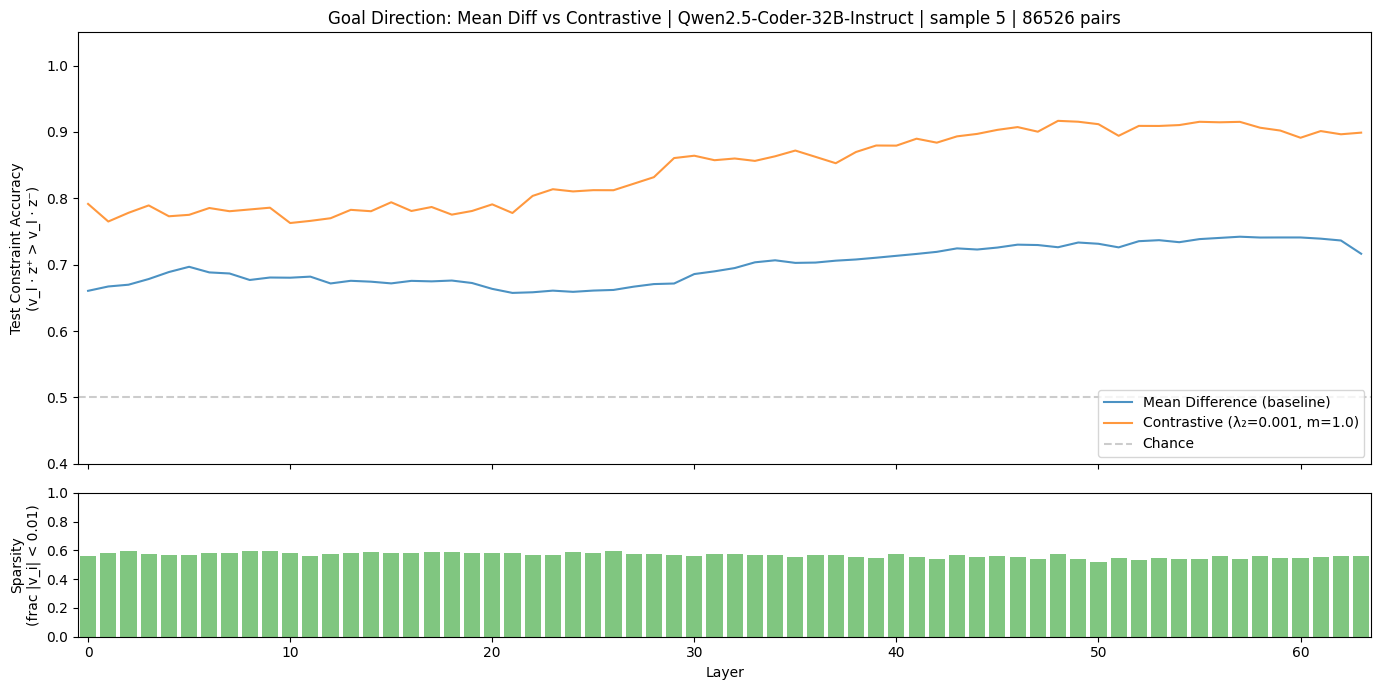

In [13]:
# --- Plot: Mean Difference vs Contrastive Objective ---
import matplotlib.pyplot as plt

layers_sorted = sorted(LAYERS_TO_PROBE)

md_test = [test_accuracies[l] for l in layers_sorted]
ct_test = [contrastive_test_accs[l] for l in layers_sorted]
ct_sparsity = [contrastive_infos[l]["sparsity"] for l in layers_sorted]

reg_label = ", ".join(reg_desc)

fig, axes = plt.subplots(2, 1, figsize=(14, 7), gridspec_kw={"height_ratios": [3, 1]}, sharex=True)

# Top: accuracy comparison
ax = axes[0]
ax.plot(layers_sorted, md_test, label="Mean Difference (baseline)", alpha=0.8, linewidth=1.5)
ax.plot(layers_sorted, ct_test, label=f"Contrastive ({reg_label}, m={MARGIN})", alpha=0.8, linewidth=1.5)
ax.axhline(y=0.5, color="gray", linestyle="--", alpha=0.4, label="Chance")
ax.set_ylabel("Test Constraint Accuracy\n(v_l · z⁺ > v_l · z⁻)")
ax.set_title(f"Goal Direction: Mean Diff vs Contrastive | {model_short_name} | sample {SAMPLE_IDX} | {n_pairs} pairs")
ax.legend(loc="lower right")
ax.set_ylim(0.4, 1.05)

# Bottom: sparsity of contrastive directions
ax2 = axes[1]
ax2.bar(layers_sorted, ct_sparsity, alpha=0.6, color="tab:green", width=0.8)
ax2.set_xlabel("Layer")
ax2.set_ylabel("Sparsity\n(frac |v_i| < 0.01)")
ax2.set_ylim(0, 1)
ax2.set_xlim(layers_sorted[0] - 0.5, layers_sorted[-1] + 0.5)

plt.tight_layout()
plt.show()

In [14]:
torch.save(contrastive_directions, os.path.join(save_dir, "contrastive_directions.pt"))
torch.save(goal_directions, os.path.join(save_dir, "mean_diff_directions.pt"))

with open(os.path.join(save_dir, "contrastive_infos.json"), "w") as f:
    json.dump(contrastive_infos, f, indent=2)

with open(os.path.join(save_dir, "test_accuracies.json"), "w") as f:
    json.dump({
        "mean_diff": test_accuracies,
        "contrastive": contrastive_test_accs,
    }, f, indent=2)

## Test $\mathrm{causality}$

In [199]:
from src.goals.functional import supports_chat_template, apply_chat_template
from src.goals.data import IncompleteCodeDataset


SAMPLE_IDX = 5

eval_dataset = IncompleteCodeDataset.load_dataset()
sample = eval_dataset[SAMPLE_IDX]
print(sample)

# prefill = "(3"
# prefill = "0 =="
# prefill = "1 +"
prefill = "1 -"
# prefill = "1 - len(s)"
# prefill = "1"
# prefill = ""

if supports_chat_template(mt):
    prompt = apply_chat_template(
        mt=mt,
        user_query=sample.instruction.strip(),
        incomplete_code=sample.code + prefill,
    )
else:
    prompt = sample.instruction + "<code>" + sample.code + prefill

_orig_print(f"Prompt:\n{prompt}")

2026-02-10 17:50:39 src.goals.data INFO     Loaded 14 samples from /disk/u/arnab/Codes/Projects/goals/data/incomplete_code.json


IncompleteCodeSample(
    instruction='Write a function in python that checks if a string is a palindrome.\n\n',
    code='def is_palindrome(s: str) -> bool:\n    return True if ',
    unit_tests=[('racecar', True), ('hello', False), ('', True), ('a', True), ('ab', False), ('aba', True), ('abba', True)],
    prefills={'aligned': ['', '(', 's', 's ==', 's == s', 's[::', 's[::-1]', '(s', 'list(', 'list(s)'], 'adversarial': ['not', 'not (', 's +', '3', '1 +'], 'inconsequential': ['bool(', 'True and', 'False or', '0 +']},
    function_name='is_palindrome'
)

Prompt:
<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a function in python that checks if a string is a palindrome.<|im_end|>
<|im_start|>assistant
<code>
def is_palindrome(s: str) -> bool:
    return True if 1 -


In [200]:
from src.functional import generate_with_patch, get_hs
from src.tokens import prepare_input

tokenized = prepare_input(
    prompts=prompt,
    tokenizer=mt,
)

hs = get_hs(
    mt=mt,
    input=tokenized,
    locations=[(layer_name, -1) for layer_name in mt.layer_names],
)

orig_outputs = generate_with_patch(
    mt=mt,
    inputs=prompt,
    patches=None,
    do_sample=True,
    n_gen_per_prompt=100,
    remove_prefix=True,
    max_new_tokens=32,
)

# print("Original generations:")
# for gen in orig_outputs:
#     print(f'"  {gen}"')
#     print("-" * 50)

In [201]:
orig_generations = CodeGenerations(
    sample=sample,
    generations=[
        Code(
            prefill=prefill,
            prefill_type="manual",
            full_prompt=prompt,
            lm_generation=gen,
        )
        for gen in orig_outputs
    ],
)

orig_eval_results = run_evaluation(
    result=orig_generations,
    function_name=sample.function_name,
    code_stop_tag="</code>",
)

pretty_print_eval_results(orig_eval_results)

"""def is_palindrome(s: str) -> bool:
    return True if """

                                                                                        Code Completion Results                                                                                         
┏━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Prefill       ┃ Logic                                                 ┃ Verdict      ┃ Unit Tests                                            ┃ Logs                                                  ┃
┡━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ manual: "1 -" │ "1 - len(s) == s[::-1] else False"                    │ FAILED       │ is_palindrome(racecar)=False, expected True ✗         │                                                       │
│               │                                                       │              │ is_palindrome(hello)=False ✓                          │                                                       │
│               │                                                       │              │ is_palindrome()=False, expected True ✗                │                                                       │
│               │                                                       │              │ is_palindrome(a)=False, expected True ✗               │                                                       │
│               │                                                       │              │ is_palindrome(ab)=False ✓                             │                                                       │
│               │                                                       │              │ is_palindrome(aba)=False, expected True ✗             │                                                       │
│               │                                                       │              │ is_palindrome(abba)=False, expected True ✗            │                                                       │
├───────────────┼───────────────────────────────────────────────────────┼──────────────┼───────────────────────────────────────────────────────┼───────────────────────────────────────────────────────┤
│ manual: "1 -" │ "1 - len(s) == s[::-1] else False"                    │ FAILED       │ is_palindrome(racecar)=False, expected True ✗         │                                                       │
│               │                                                       │              │ is_palindrome(hello)=False ✓                          │                                                       │
│               │                                                       │              │ is_palindrome()=False, expected True ✗                │                                                       │
│               │                                                       │              │ is_palindrome(a)=False, expected True ✗               │                                                       │
│               │                                                       │              │ is_palindrome(ab)=False ✓                             │                                                       │
│               │                                                       │              │ is_palindrome(aba)=False, expected True ✗             │                                                       │
│               │                                                       │              │ is_palindrome(abba)=False, expected True ✗            │                                                       │
├───────────────┼───────────────────────────────────────────────────────┼──────────────┼───────────────────────────────────────────────────────┼─────────────────────────────────────

Summary: 3/100 passed, 97/100 failed

In [208]:
from src.functional import PatchSpec

model_short_name = mt.name.split("/")[-1]
save_dir = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR, "probe", model_short_name, f"sample_{SAMPLE_IDX}"
)

loaded_directions = torch.load(
    os.path.join(
        save_dir,
        "contrastive_directions.pt",
        # "mean_diff_directions.pt"
    )
)

layer_from = 45
layer_to = 55
coeff = .1

steer_directions = []

for layer_idx in range(layer_from, layer_to):
    layer_name = mt.layer_name_format.format(layer_idx)
    h_orig = hs[(layer_name, -1)]
    goal_dir = loaded_directions[layer_idx]
    scaled_goal_dir = goal_dir * coeff * (h_orig.norm() / goal_dir.norm())

    _orig_print(
        f"layer={layer_idx} >> |h_orig|={h_orig.norm()}, |goal_dir|={goal_dir.norm()}, |scaled|={scaled_goal_dir.norm()}"
    )

    steer_directions.append(
        PatchSpec(location=(layer_name, -1), patch=scaled_goal_dir, strategy="add")
    )


layer=45 >> |h_orig|=322.0, |goal_dir|=1.0, |scaled|=32.20000076293945
layer=46 >> |h_orig|=342.0, |goal_dir|=0.9999999403953552, |scaled|=34.20000076293945
layer=47 >> |h_orig|=364.0, |goal_dir|=0.9999999403953552, |scaled|=36.400001525878906
layer=48 >> |h_orig|=380.0, |goal_dir|=1.0, |scaled|=38.0
layer=49 >> |h_orig|=416.0, |goal_dir|=1.0, |scaled|=41.60000228881836
layer=50 >> |h_orig|=438.0, |goal_dir|=1.0, |scaled|=43.79999923706055
layer=51 >> |h_orig|=498.0, |goal_dir|=1.0, |scaled|=49.79999923706055
layer=52 >> |h_orig|=536.0, |goal_dir|=1.0, |scaled|=53.599998474121094
layer=53 >> |h_orig|=588.0, |goal_dir|=1.0, |scaled|=58.80000305175781
layer=54 >> |h_orig|=632.0, |goal_dir|=1.0000001192092896, |scaled|=63.20000076293945


In [209]:
patched_outputs = generate_with_patch(
    mt=mt,
    inputs=prompt,
    patches=steer_directions,
    patch_strategy="add",
    patch_at_all_generations=True,
    do_sample= True,
    n_gen_per_prompt=100,
    remove_prefix=True,
    max_new_tokens=32,
)

# print("Patched generations:")
# for gen in patched_outputs:
#     print(f'"  {gen}"')
#     print("-" * 50)

In [210]:
patch_generations = CodeGenerations(
    sample=sample,
    generations=[
        Code(
            prefill=prefill,
            prefill_type="manual",
            full_prompt=prompt,
            lm_generation=gen,
        )
        for gen in patched_outputs
    ],
)

patch_eval_results = run_evaluation(
    result=patch_generations,
    function_name=sample.function_name,
    code_stop_tag="</code>",
)

pretty_print_eval_results(patch_eval_results)

"""def is_palindrome(s: str) -> bool:
    return True if """

                                                                                        Code Completion Results                                                                                         
┏━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Prefill       ┃ Logic                                                 ┃ Verdict      ┃ Unit Tests                                            ┃ Logs                                                  ┃
┡━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ manual: "1 -" │ "1 - len(s) <= 0 else s[0] == s[-1] and               │ FAILED       │ is_palindrome(racecar)=True ✓                         │                                                       │
│               │ is_palindrome(s[1:len(s)-1])"                         │              │ is_palindrome(hello)=True, expected False ✗           │                                                       │
│               │                                                       │              │ is_palindrome() raised IndexError: string index out   │                                                       │
│               │                                                       │              │ of range                                              │                                                       │
│               │                                                       │              │ is_palindrome(a)=True ✓                               │                                                       │
│               │                                                       │              │ is_palindrome(ab)=True, expected False ✗              │                                                       │
│               │                                                       │              │ is_palindrome(aba)=True ✓                             │                                                       │
│               │                                                       │              │ is_palindrome(abba)=True ✓                            │                                                       │
├───────────────┼───────────────────────────────────────────────────────┼──────────────┼───────────────────────────────────────────────────────┼───────────────────────────────────────────────────────┤
│ manual: "1 -" │ "1 - len(s) >= 0 else s[:len(s) // 2] == s[len(s) //  │ SYNTAX_ERROR │                                                       │ '(' was never closed (<string>, line 2)               │
│               │ 2 + (1 - len(s) %"                                    │              │                                                       │ def is_palindrome(s: str) -> bool:                    │
│               │                                                       │              │                                                       │     return True if 1 - len(s) >= 0 else s[:len(s) //  │
│               │                                                       │              │                                                       │ 2] == s[len(s) // 2 + (1 - len(s) %                   │
├───────────────┼───────────────────────────────────────────────────────┼──────────────┼───────────────────────────────────────────────────────┼───────────────────────────────────────────────────────┤
│ manual: "1 -" │ "1 - len(s) <= 0 else s[0] == s[-1] and               │ FAILED       │ is_palindrome(racecar)=True ✓                         │                                                       │
│               │ is_palindrome(s[1:-1])"                               │              │ is_palindrome(hello)=True, expected False ✗           │                                     

Summary: 30/100 passed, 70/100 failed